# Étude de la pollution des stations de la RATP

Ce notebook analyse le jeu de données d'Île-de-France Mobilités sur la qualité de l'air dans les stations souterraines du réseau francilien, réalisé avec Airparif. On charge d'abord les données brutes puis on les nettoie avant de calculer un niveau de pollution moyen par ligne.

Le fichier est téléchargé directement depuis la source officielle au moment de l'exécution. Les noms exacts de colonnes sont détectés automatiquement dans le code (via des mots clés comme « pollution » ou « ligne ») car ils peuvent varier légèrement d'un export à l'autre, donc vérifie bien l'affichage des colonnes à la cellule suivante avant de poursuivre.

In [1]:
import pandas as pd
import numpy as np
import unicodedata
import matplotlib.pyplot as plt

URL = "https://www.data.gouv.fr/api/1/datasets/r/efb9ab99-4c52-4722-be5a-245c5322ab33"

try:
    df = pd.read_csv(URL, sep=";")
    if df.shape[1] == 1:
        raise ValueError("separateur incorrect")
except Exception:
    df = pd.read_csv(URL, sep=",")

print(df.shape)

(665, 19)


On regarde les 10 premières lignes du jeu de données ainsi que la liste complète des colonnes disponibles.

In [2]:
df.head(10)

,Identifiant station,Nom de la Station,Nom de la ligne,Niveau de pollution aux particules,Niveau de pollution,Incertitude,Recommandation de surveillance,Action(s) QA en cours,Lien vers les mesures en direct,Durée des mesures,Mesures d’amélioration mises en place ou prévues,stop_lon,stop_lat,point_geo,pollution_air,air,niveau,actions,niveau_pollution
0,IDFM:monomodalStopPlace:46387,Ablon,RER C,station aérienne,station aérienne,NaN,non,NaN,https://www.airparif.fr/,NaN,NaN,2.419867,48.725781,"48.72578126379895, 2.4198671478914595",station aérienne,NaN,Station aérienne – Proche des niveaux en air e...,NaN,station aérienne
1,IDFM:490917,Aéroport d'Orly,Métro 14,pas de données,pas de données,Évaluation : impossible faute d’informations,non,NaN,NaN,NaN,NaN,2.362615,48.728273,"48.72827304426601, 2.3626148529686626",pas de données,NaN,Pas de données,NaN,pas de données
2,IDFM:463118,Alésia,Métro 4,pollution faible,FAIBLE,Évaluation : modélisation reposant notamment s...,non,NaN,NaN,NaN,NaN,2.327193,48.828152,"48.828152157703514, 2.3271926250651647",pollution faible - incertitude forte,NaN,Pollution faible,NaN,pollution faible
3,IDFM:22122,Alexandre Dumas,Métro 2,pollution moyenne,MOYENNE,Évaluation : campagne de mesure ponctuelle,non,Action(s) d'amélioration de la qualité de l'ai...,NaN,campagne de mesure ponctuelle,NaN,2.394825,48.856002,"48.85600242440136, 2.3948253985144294",pollution moyenne - incertitude faible,NaN,Pollution moyenne,NaN,pollution moyenne
4,IDFM:463121,Argentine,Métro 1,pollution faible,FAIBLE,Évaluation : modélisation reposant notamment s...,non,NaN,NaN,NaN,NaN,2.290095,48.875276,"48.87527558076666, 2.290095209729821",pollution faible - incertitude forte,NaN,Pollution faible,NaN,pollution faible
5,IDFM:monomodalStopPlace:43068,Arpajon,RER C,station aérienne,station aérienne,NaN,non,NaN,https://www.airparif.fr/,NaN,NaN,2.241217,48.585997,"48.58599680822646, 2.2412169696111426",station aérienne,NaN,Station aérienne – Proche des niveaux en air e...,NaN,station aérienne
6,IDFM:22233,Asnières - Gennevilliers Les Courtilles,Métro 13,pollution faible,FAIBLE,Évaluation : modélisation reposant notamment s...,non,NaN,NaN,NaN,NaN,2.284220,48.930765,"48.93076460500162, 2.2842197492931637",pollution faible - incertitude forte,NaN,Pollution faible,NaN,pollution faible
7,IDFM:monomodalStopPlace:43071,Aulnay-sous-Bois,RER B,station aérienne,station aérienne,NaN,non,NaN,https://www.airparif.fr/,NaN,NaN,2.495597,48.932151,"48.932150935734064, 2.495597257086315",station aérienne,NaN,Station aérienne – Proche des niveaux en air e...,NaN,station aérienne
8,IDFM:463124,Avenue Emile Zola,Métro 10,pollution moyenne,MOYENNE,Évaluation : modélisation reposant notamment s...,non,Action(s) d'amélioration de la qualité de l'ai...,NaN,NaN,NaN,2.294637,48.846991,"48.84699079226385, 2.2946367205063405",pollution moyenne - incertitude forte,NaN,Pollution moyenne,NaN,pollution moyenne
9,IDFM:monomodalStopPlace:45437,Avenue Foch,RER C,pollution moyenne,MOYENNE,Évaluation : campagne de mesure ponctuelle,non,NaN,NaN,campagne de mesure ponctuelle,NaN,2.274771,48.869853,"48.86985281215763, 2.2747712644338454",pollution moyenne - incertitude faible,NaN,Pollution moyenne,NaN,pollution moyenne


In [3]:
print(df.columns.tolist())

['Identifiant station', 'Nom de la Station', 'Nom de la ligne', 'Niveau de pollution aux particules', 'Niveau de pollution', 'Incertitude', 'Recommandation de surveillance', 'Action(s) QA en cours', 'Lien vers les mesures en direct', 'Durée des mesures', 'Mesures d’amélioration mises en place ou prévues', 'stop_lon', 'stop_lat', 'point_geo', 'pollution_air', 'air', 'niveau', 'actions', 'niveau_pollution']


Pour notre étude on n'a pas besoin des coordonnées GPS ni des autres colonnes techniques situées au milieu du tableau. On garde uniquement les 4 premières colonnes et les 3 dernières, le reste est coupé.

In [4]:
df = pd.concat([df.iloc[:, :4], df.iloc[:, -3:]], axis=1)
df.head(10)

,Identifiant station,Nom de la Station,Nom de la ligne,Niveau de pollution aux particules,niveau,actions,niveau_pollution
0,IDFM:monomodalStopPlace:46387,Ablon,RER C,station aérienne,Station aérienne – Proche des niveaux en air e...,NaN,station aérienne
1,IDFM:490917,Aéroport d'Orly,Métro 14,pas de données,Pas de données,NaN,pas de données
2,IDFM:463118,Alésia,Métro 4,pollution faible,Pollution faible,NaN,pollution faible
3,IDFM:22122,Alexandre Dumas,Métro 2,pollution moyenne,Pollution moyenne,NaN,pollution moyenne
4,IDFM:463121,Argentine,Métro 1,pollution faible,Pollution faible,NaN,pollution faible
5,IDFM:monomodalStopPlace:43068,Arpajon,RER C,station aérienne,Station aérienne – Proche des niveaux en air e...,NaN,station aérienne
6,IDFM:22233,Asnières - Gennevilliers Les Courtilles,Métro 13,pollution faible,Pollution faible,NaN,pollution faible
7,IDFM:monomodalStopPlace:43071,Aulnay-sous-Bois,RER B,station aérienne,Station aérienne – Proche des niveaux en air e...,NaN,station aérienne
8,IDFM:463124,Avenue Emile Zola,Métro 10,pollution moyenne,Pollution moyenne,NaN,pollution moyenne
9,IDFM:monomodalStopPlace:45437,Avenue Foch,RER C,pollution moyenne,Pollution moyenne,NaN,pollution moyenne


On définit une petite fonction de normalisation (minuscules, sans accents) pour repérer les colonnes et les valeurs sans être gêné par la casse ou les accents. On repère ainsi la colonne du niveau de pollution et celle de la ligne de transport.

In [5]:
def normalize(s):
    if pd.isna(s):
        return s
    s = str(s).strip().lower()
    s = "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))
    return s

def find_col(dataframe, keyword):
    for c in dataframe.columns:
        if keyword in normalize(c):
            return c
    return None

pol_col = find_col(df, "pollution")
ligne_col = find_col(df, "ligne")
print("colonne pollution :", pol_col)
print("colonne ligne :", ligne_col)

colonne pollution : Niveau de pollution aux particules
colonne ligne : Nom de la ligne


On affiche les différentes valeurs présentes dans la colonne du niveau de pollution, sans doublons, pour connaître les catégories utilisées et repérer les absences de mesure.

In [6]:
print(df[pol_col].unique())
print("valeurs manquantes :", df[pol_col].isna().sum())

['station aérienne' 'pas de données' 'pollution faible'
 'pollution moyenne' 'pollution élevée']
valeurs manquantes : 0


On remplace les absences de mesure par la catégorie moyenne, qui sert de valeur par défaut la plus neutre en l'absence d'information.

In [7]:
df[pol_col] = df[pol_col].fillna("moyen")
print(df[pol_col].isna().sum())

0


On ajoute une colonne numérique « valeur pollution » à partir de la catégorie textuelle, avec la correspondance suivante : station aérienne = 0.5, faible = 1, moyen = 2, élevé = 3.

In [8]:
mapping = {
    "station aerienne": 0.5,
    "pas de données": 0.5,
    "pollution faible": 1,
    "pollution moyenne": 2,
    "pollution élevée": 3,
}

df["valeur pollution"] = df[pol_col].apply(lambda x: mapping.get(normalize(x), np.nan))

non_reconnues = df.loc[df["valeur pollution"].isna(), pol_col].unique()
if len(non_reconnues) > 0:
    print("valeurs non reconnues par le mapping :", non_reconnues)

df[[pol_col, "valeur pollution"]].head(10)

valeurs non reconnues par le mapping : ['pas de données' 'pollution élevée']


,Niveau de pollution aux particules,valeur pollution
0,station aérienne,0.5
1,pas de données,NaN
2,pollution faible,1.0
3,pollution moyenne,2.0
4,pollution faible,1.0
5,station aérienne,0.5
6,pollution faible,1.0
7,station aérienne,0.5
8,pollution moyenne,2.0
9,pollution moyenne,2.0


On calcule, pour chaque ligne de transport, la somme des niveaux de pollution divisée par le nombre de stations de cette ligne. Ce calcul inclut ici toutes les stations, y compris les stations aériennes.

In [9]:
grouped_all = df.groupby(ligne_col)["valeur pollution"].agg(["sum", "count"])
grouped_all["pollution_moyenne"] = grouped_all["sum"] / grouped_all["count"]

top10_all = grouped_all.sort_values("pollution_moyenne", ascending=False).head(10)
bottom10_all = grouped_all.sort_values("pollution_moyenne", ascending=True).head(10)

print("10 lignes les plus polluées (toutes stations) :")
display(top10_all)
print("10 lignes les moins polluées (toutes stations) :")
display(bottom10_all)

10 lignes les plus polluées (toutes stations) :


,sum,count,pollution_moyenne
Nom de la ligne,,,
L,2.0,1,2.000000
Métro 7B,16.0,8,2.000000
Métro 3B,8.0,4,2.000000
U,2.0,1,2.000000
Métro 9,73.0,37,1.972973
Métro 5,35.0,19,1.842105
Métro 10,41.0,23,1.782609
Métro 3,44.0,25,1.760000
Métro 2,41.0,24,1.708333


10 lignes les moins polluées (toutes stations) :


,sum,count,pollution_moyenne
Nom de la ligne,,,
RER E,16.0,26,0.615385
RER D,36.5,59,0.618644
RER B,32.5,47,0.691489
RER C,55.5,79,0.702532
RER A,40.5,46,0.880435
Métro 4,34.0,29,1.172414
Métro 6,35.5,28,1.267857
Métro 13,43.0,32,1.343750
Métro 1,34.0,25,1.360000


On refait le même calcul en excluant cette fois les stations aériennes, aussi bien dans la somme des niveaux de pollution que dans le nombre de stations comptées. On vérifie d'abord qu'il reste au moins une station non aérienne par ligne pour éviter une division par zéro.

In [10]:
mask_non_aerien = df[pol_col].apply(lambda x: normalize(x) != "station aerienne")
df_non_aerien = df[mask_non_aerien]

lignes_toutes = set(df[ligne_col].unique())
lignes_non_aerien = set(df_non_aerien[ligne_col].unique())
lignes_exclues = lignes_toutes - lignes_non_aerien

if len(lignes_exclues) > 0:
    print("lignes exclues car aucune station non aerienne :", lignes_exclues)
else:
    print("chaque ligne possede au moins une station non aerienne")

grouped_sol = df_non_aerien.groupby(ligne_col)["valeur pollution"].agg(["sum", "count"])
grouped_sol["pollution_moyenne"] = grouped_sol["sum"] / grouped_sol["count"]

top10_sol = grouped_sol.sort_values("pollution_moyenne", ascending=False).head(10)
bottom10_sol = grouped_sol.sort_values("pollution_moyenne", ascending=True).head(10)

print("10 lignes les plus polluees (stations souterraines uniquement) :")
display(top10_sol)
print("10 lignes les moins polluees (stations souterraines uniquement) :")
display(bottom10_sol)

chaque ligne possede au moins une station non aerienne
10 lignes les plus polluees (stations souterraines uniquement) :


,sum,count,pollution_moyenne
Nom de la ligne,,,
L,2.0,1,2.000000
Métro 5,34.0,17,2.000000
Métro 3B,8.0,4,2.000000
U,2.0,1,2.000000
Métro 7B,16.0,8,2.000000
Métro 9,73.0,37,1.972973
Métro 2,39.0,20,1.950000
Métro 6,29.0,15,1.933333
Métro 10,41.0,23,1.782609


10 lignes les moins polluees (stations souterraines uniquement) :


,sum,count,pollution_moyenne
Nom de la ligne,,,
Métro 4,34.0,29,1.172414
RER E,5.0,4,1.250000
Métro 1,34.0,25,1.360000
Métro 13,42.0,30,1.400000
Métro 8,51.0,34,1.500000
Métro 11,28.0,18,1.555556
RER B,13.0,8,1.625000
RER C,23.0,14,1.642857
RER A,25.0,15,1.666667


On remarque qu'en ne tenant plus compte des stations aeriennes, des lignes dans un premier temps jugées comme faisant parti des mlus poluées s'averrent etre en realité faisant parti des plus poluées comme par exemple le RER A qui passe de 0,90 à 1,73

On visualise enfin la relation entre le nombre de stations d'une ligne et son niveau de pollution moyen, un point représentant une ligne de transport. Premier nuage de points avec toutes les stations.

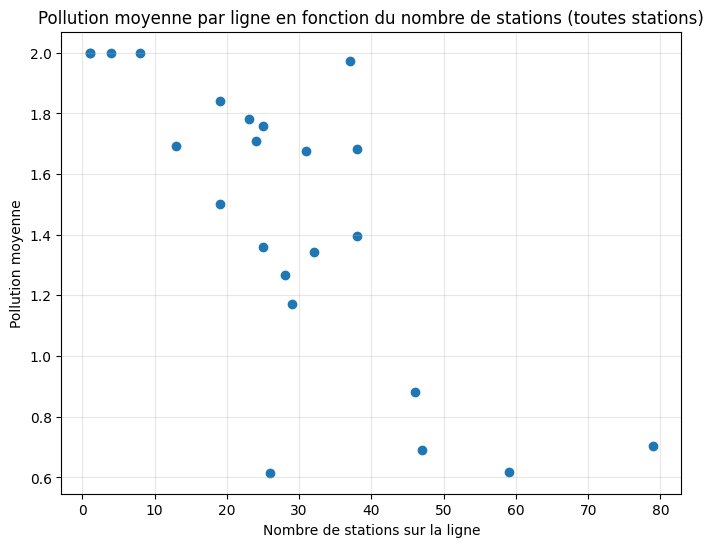

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(grouped_all["count"], grouped_all["pollution_moyenne"])
plt.xlabel("Nombre de stations sur la ligne")
plt.ylabel("Pollution moyenne")
plt.title("Pollution moyenne par ligne en fonction du nombre de stations (toutes stations)")
plt.grid(True, alpha=0.3)
plt.show()

Second nuage de points, cette fois en ne comptabilisant que les stations souterraines.

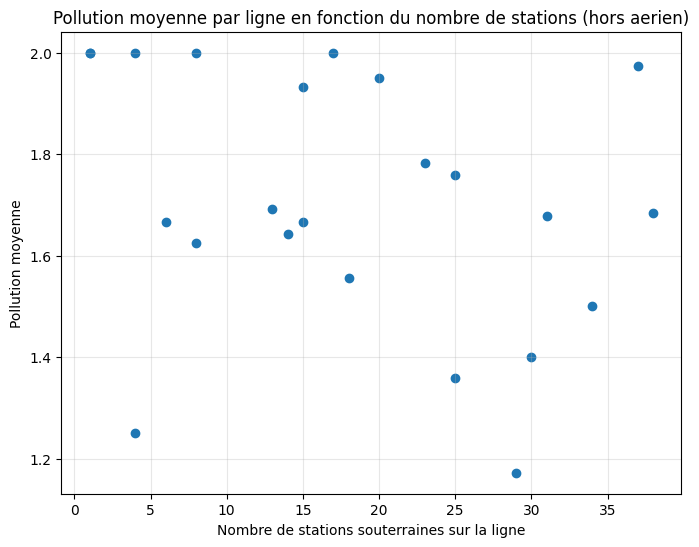

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(grouped_sol["count"], grouped_sol["pollution_moyenne"])
plt.xlabel("Nombre de stations souterraines sur la ligne")
plt.ylabel("Pollution moyenne")
plt.title("Pollution moyenne par ligne en fonction du nombre de stations (hors aerien)")
plt.grid(True, alpha=0.3)
plt.show()

Quel ligne a le plus de stations à pollution elevée ?
y a t il une correlation entre nombre de ligne passant pasant par une station et pollution de la station ?
Recherche de correlation entre pollution d'une ligne et age des rames utilisées.